In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
import autoroot
from paper_plots.plot_config import set_plot_style

from src.utils.result_processing import MODEL_KEY_REGISTRY


font_size = 55
lw=4
figsize = (12,8)

# Apply consistent styling
set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette='Spectral',legend_font_size=40)
# loss = 'val/rLoss1_epoch'
loss = 'train/rLoss_epoch.min'

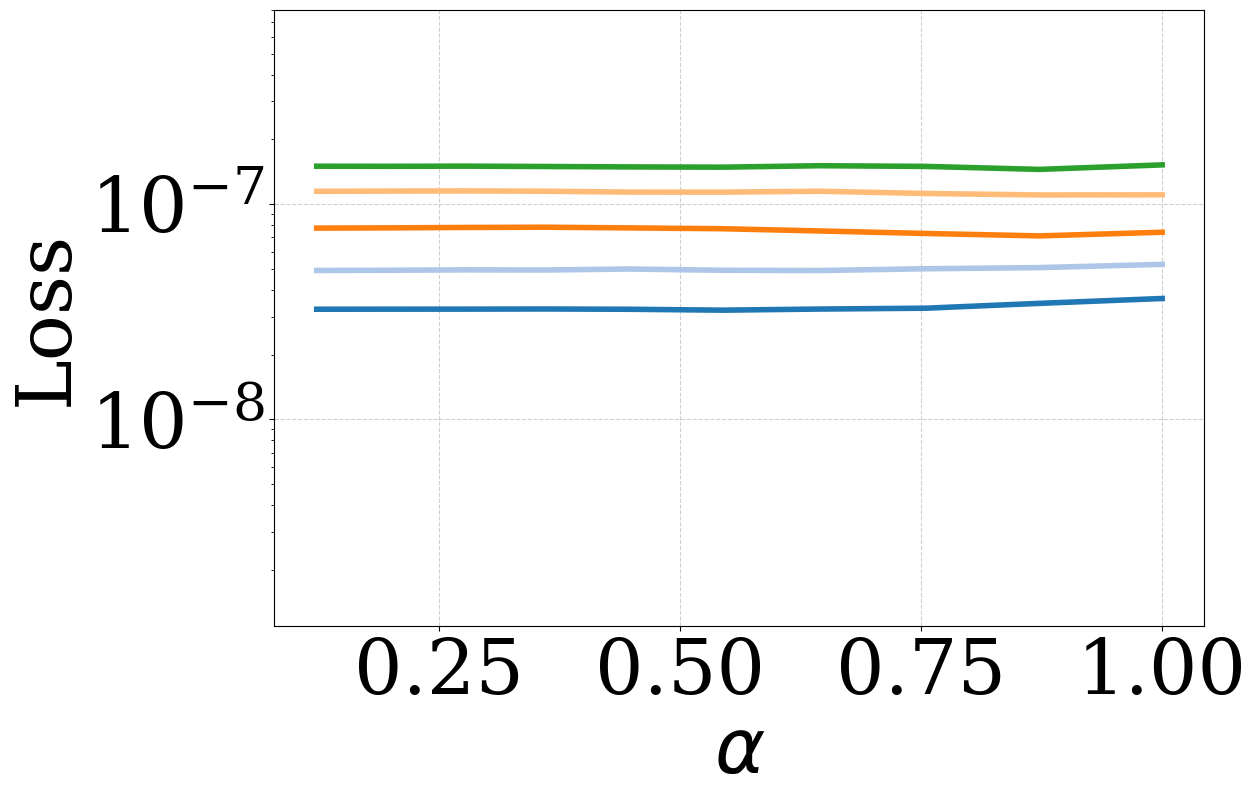

In [3]:

m_key = 'module.layers.LSTM.num_layers'
df = pd.read_pickle(f"../../results/Multilayer_LSTM_exp_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
# df_min = df_min[df_min['m']>4]
# df_min = df_min[df_min['m']<256]

fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')
ax1.set_ylabel('Loss')
ax1.set_ylim(1.1*1e-9, 0.8*1e-6)
plt.savefig('Multilayer_LSTM_exp.pdf', bbox_inches='tight')


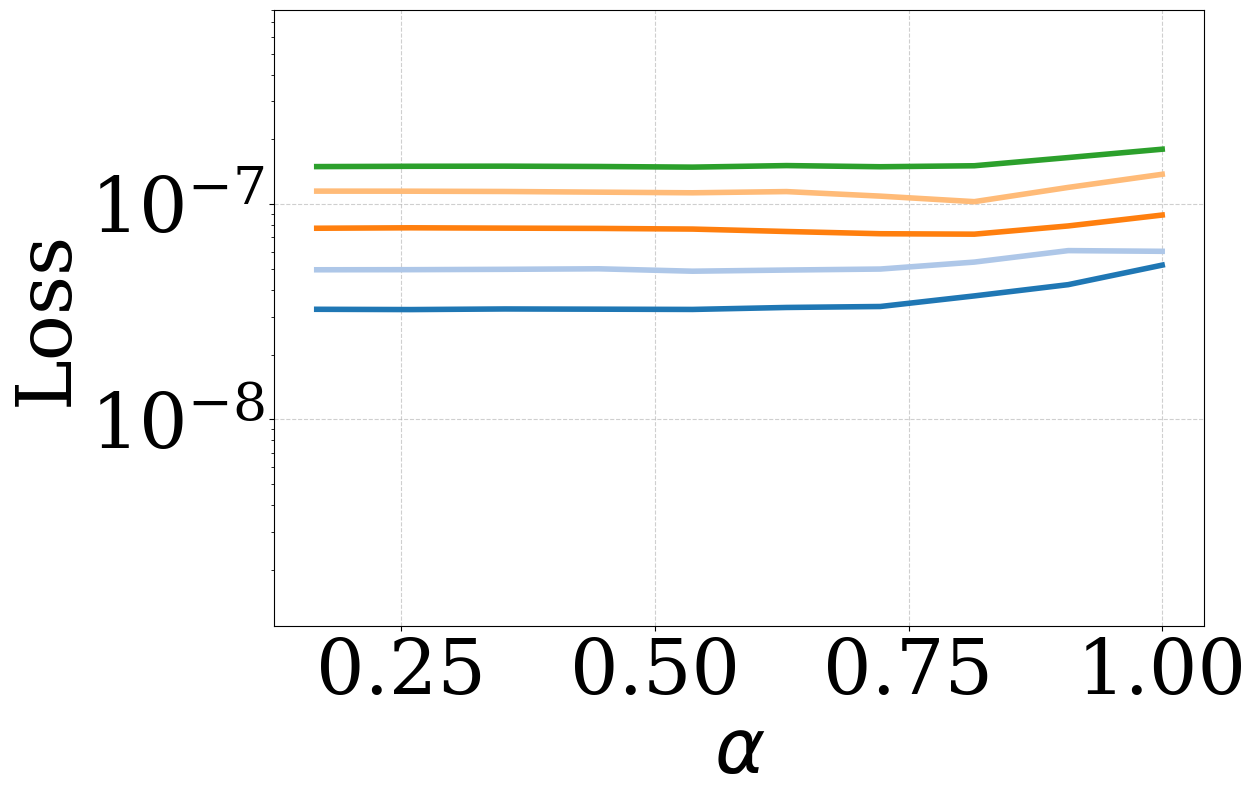

In [4]:

m_key = 'module.layers.LSTM.num_layers'
df = pd.read_pickle(f"../../results/Multilayer_LSTM_poly_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
ax1.set_ylim(1.1*1e-9, 0.8*1e-6)
plt.savefig('Multilayer_LSTM_poly.pdf', bbox_inches='tight')


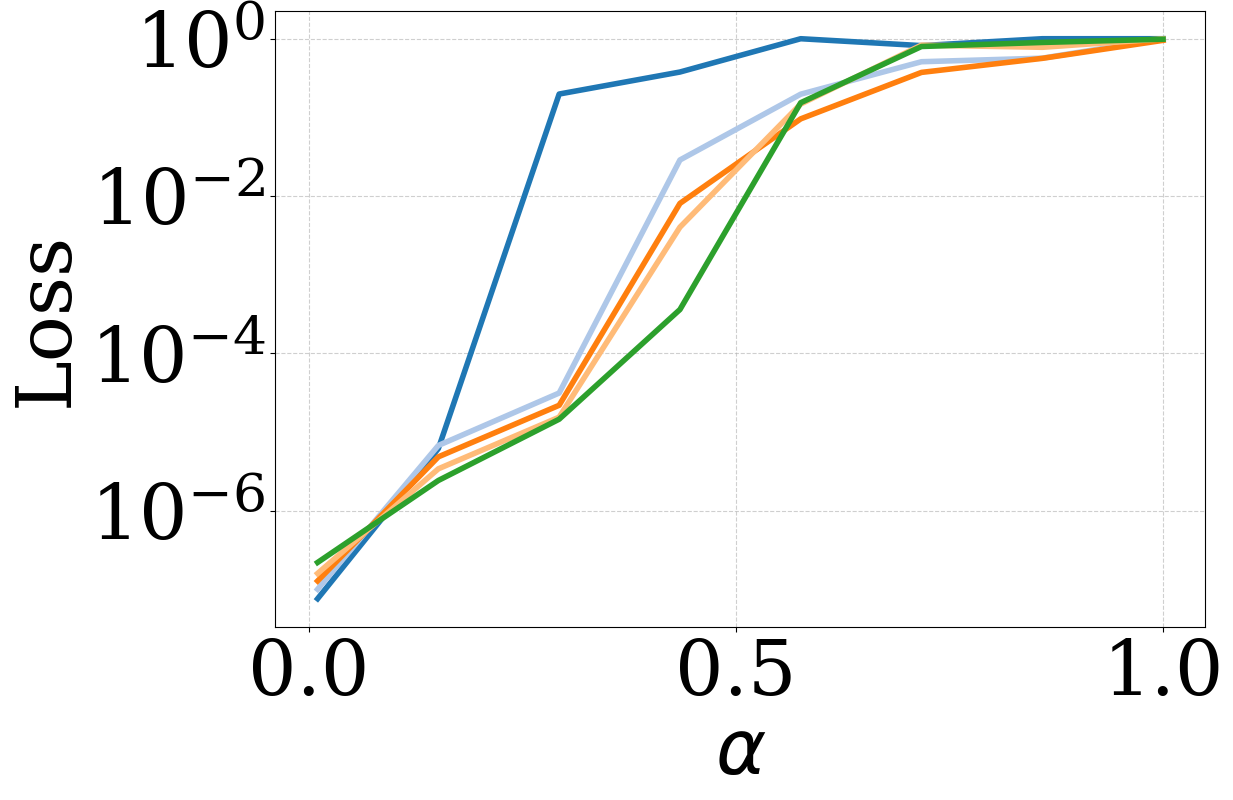

In [5]:

m_key = 'module.layers.LSTM.num_layers'
df = pd.read_pickle(f"../../results/Multilayer_LSTM_impulse_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()


fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
# ax1.set_ylim(1e-10, 0.8*1e-7)
plt.savefig('Multilayer_LSTM_impulse.pdf', bbox_inches='tight')


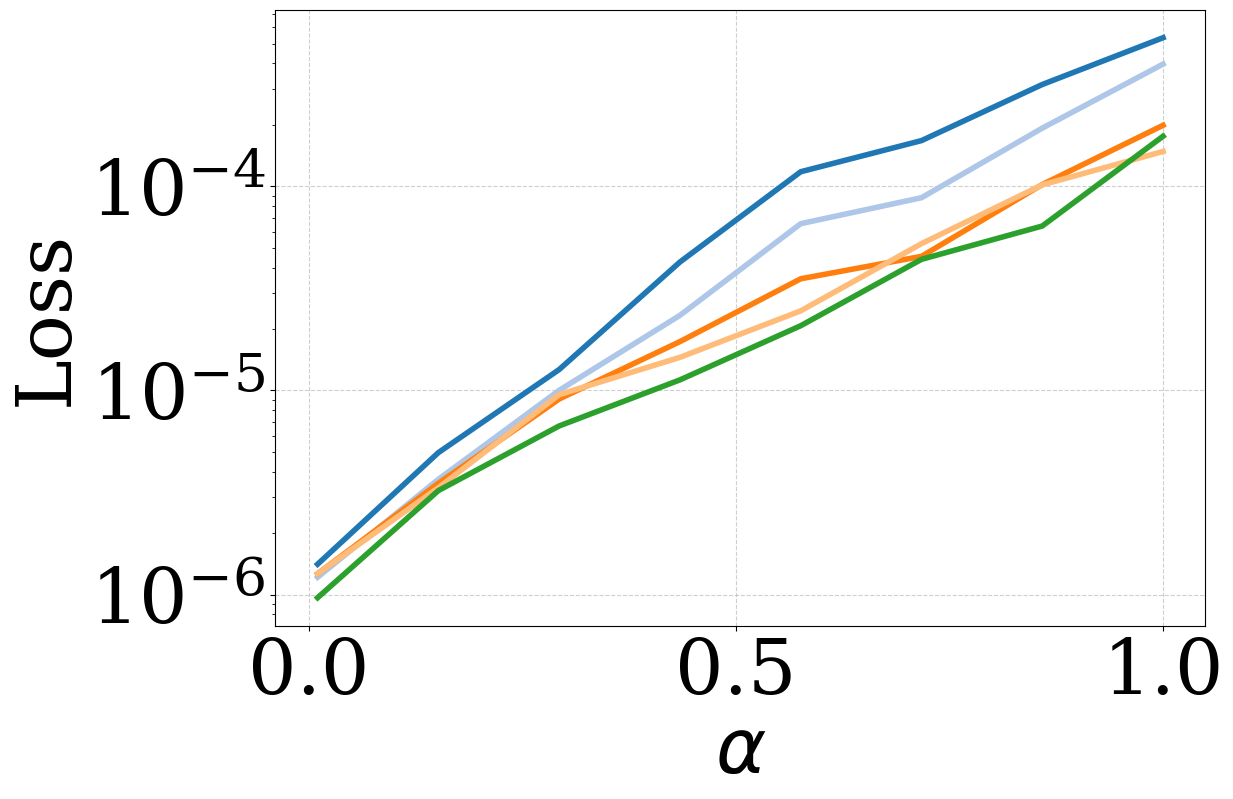

In [6]:

m_key = 'module.layers.LSTM.num_layers'
df = pd.read_pickle(f"../../results/Multilayer_LSTM_airy_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()



fig, ax1 = plt.subplots(figsize=figsize)
sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax1,
             palette='tab20', lw=lw, legend=False)



ax1.set_xlabel(r'$\alpha$')
# ax1.xaxis.set_label_coords(-0.08, 0.04)
ax1.set_yscale('log')

ax1.set_ylabel('Loss')
# ax1.set_ylim(1e-10, 0.8*1e-7)
plt.savefig('Multilayer_LSTM_airy.pdf', bbox_inches='tight')


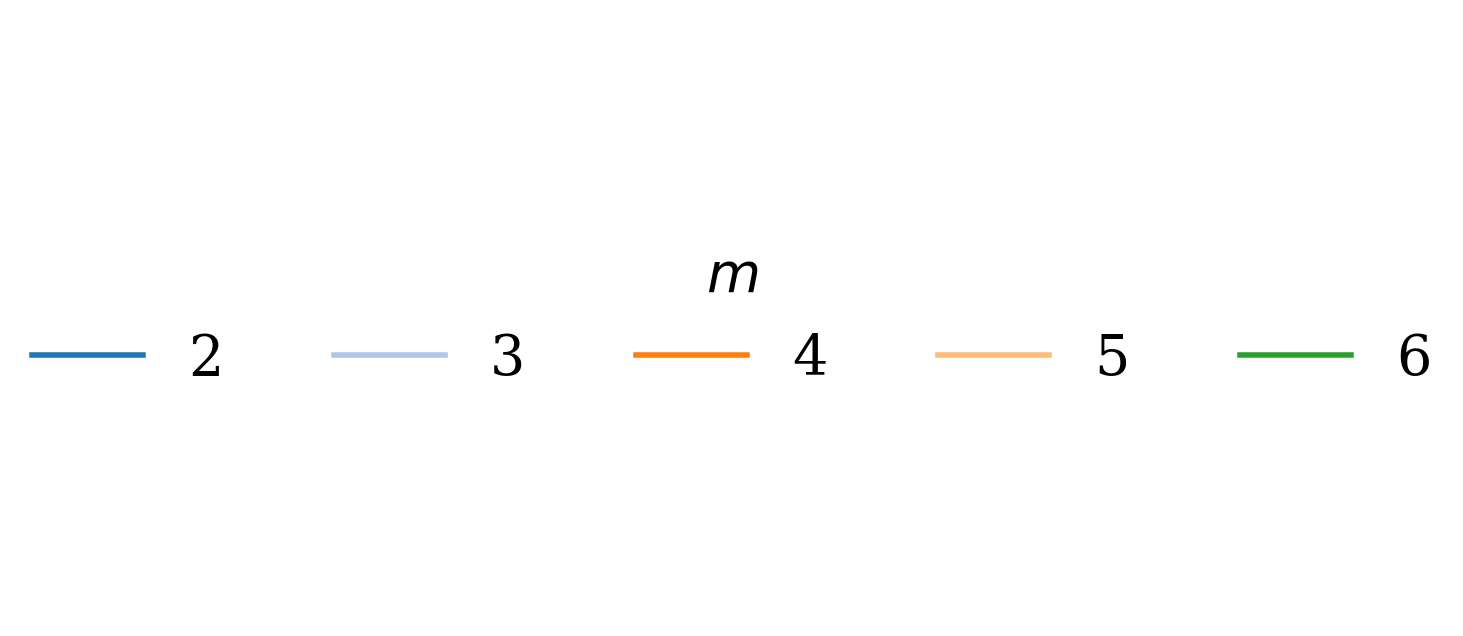

In [7]:

m_key = 'module.layers.LSTM.num_layers'
df = pd.read_pickle(f"../../results/Multilayer_LSTM_poly_data_clean.pkl")
df['m'] = df[m_key]
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()



fig, ax_legend = plt.subplots(figsize=figsize)
# Create the plot to get the legend handles
line_plot = sns.lineplot(data=df_min, x='alpha', y=loss, hue='m', ax=ax_legend,
             palette='tab20', lw=lw)

# Get handles and labels
handles, labels = ax_legend.get_legend_handles_labels()

# Clear the axis
ax_legend.clear()
ax_legend.axis('off')

# Create legend only
legend = ax_legend.legend(handles, labels, title=r'$m$', loc='center', 
                          ncol=5, frameon=False)

plt.savefig('Multilayer_LSTM_legend.pdf', bbox_inches='tight')


In [13]:
# Calculate average loss increment at largest alpha compared to smallest alpha
# averaged over different m values, for each task type

tasks = ['exp', 'poly', 'airy', 'impulse']
results = {}

for task in tasks:
    # Load data
    df = pd.read_pickle(f"../../results/Multilayer_LSTM_{task}_data_clean.pkl")
    df['m'] = df[m_key]
    df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
    
    # Get minimum loss for each (m, alpha) combination
    df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
    
    # Find the smallest and largest alpha values
    alpha_min = df_min['alpha'].min()
    alpha_max = df_min['alpha'].max()
    
    # Get losses at smallest and largest alpha
    loss_alpha_min = df_min[df_min['alpha'] == alpha_min].groupby('m')[loss].min()
    loss_alpha_max = df_min[df_min['alpha'] == alpha_max].groupby('m')[loss].min()
    
    # Calculate increment for each m
    # Using inner join to ensure we only compare when both alpha values exist
    increments = loss_alpha_max - loss_alpha_min
    
    # Calculate average increment across all m values
    avg_increment = increments.mean()
    
    # Also calculate relative increment (percentage)
    relative_increment = (increments / loss_alpha_min).mean() * 100
    
    results[task] = {
        'avg_absolute_increment': avg_increment,
        'avg_relative_increment_pct': relative_increment,
        'num_m_values': len(increments),
        'alpha_min': alpha_min,
        'alpha_max': alpha_max
    }
    
    print(f"\n{task.upper()}:")
    print(f"  Alpha range: {alpha_min:.6f} to {alpha_max:.6f}")
    print(f"  Average absolute loss increment (alpha_max vs alpha_min): {avg_increment:.6e}")
    print(f"  Average relative loss increment: {relative_increment:.2f}%")
    print(f"  Number of m values used: {len(increments)}")

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
for task in tasks:
    print(f"{task:8s}: {results[task]['avg_absolute_increment']:12.6e}  ({results[task]['avg_relative_increment_pct']:8.2f}%)")



EXP:
  Alpha range: 0.122807 to 1.000000
  Average absolute loss increment (alpha_max vs alpha_min): 3.781480e-10
  Average relative loss increment: 2.48%
  Number of m values used: 5

POLY:
  Alpha range: 0.166667 to 1.000000
  Average absolute loss increment (alpha_max vs alpha_min): 1.907732e-08
  Average relative loss increment: 27.52%
  Number of m values used: 5

AIRY:
  Alpha range: 0.010000 to 1.000000
  Average absolute loss increment (alpha_max vs alpha_min): 2.894936e-04
  Average relative loss increment: 23118.68%
  Number of m values used: 5

IMPULSE:
  Alpha range: 0.010000 to 1.000000
  Average absolute loss increment (alpha_max vs alpha_min): 9.871061e-01
  Average relative loss increment: 828257394.75%
  Number of m values used: 5

SUMMARY
exp     : 3.781480e-10  (    2.48%)
poly    : 1.907732e-08  (   27.52%)
airy    : 2.894936e-04  (23118.68%)
impulse : 9.871061e-01  (828257394.75%)
